# Quickstart guide: Your first simulation

:::{tip} Open in Lab
Run this simulation interactively in your browser with zero installation:
[Open in JupyterLite Lab](/lite/lab/index.html?path=tutorials/first-simulation.ipynb)
:::


This example, introduces basic concepts and runs a complete TVB whole-brain simulation.


## Key concepts

Each simulation requires some basic building blocks which are assembled in `tvb.simulator`. In the following tutorial, we will build them one by one and assemble them in a whole-brain model. 


1) **Model** — the local neuronal dynamics at each region: a set of ordinary
  differential equations plus their parameters ([find more details here](/bb-model/))

2) **Connectivity** — the large-scale structural connectome: a network of
  regions with white-matter tract lengths and weights between them. TVB ships
  a default 76-region dataset that these tutorials use.([find more details here](/bb-connectivity/))

3) **Coupling** — the function that joins the model dynamics at one region to
  the signals arriving from its partners ([find more details here](/bb-coupling/))

4) **Integrator** — the numerical scheme stepping the dynamics forward in time, you can set it up with or without noise ([find more details here](/bb-integrator/))

5) **{term}`Monitor <Monitor>`** — an observation process applied to the simulated activity to record the {term}`state variables <state variable>` or apply biophysical monitors (EEG, MEG, …) via the forward model ([find more details here](/bb-monitor/))


### Imports

The first thing we need to do, is to import the necessary TVB modules and some additional Python packages to perform the simulation and analyze our results.

In [15]:
%matplotlib inline
from pathlib import Path

import numpy as np
import time as tm
import matplotlib.pyplot as plt

from tvb.simulator import simulator
from tvb.simulator.lab import connectivity, coupling, integrators, models, monitors, noise

### The **Model**: Local dynamics, coupling, and integration

Within TVB, you can chose from a wide variety of local models (have a look at the [**Model Zoo**](/intro/)to learn more). Each model is described by a set of ordinary differential equations which are tuned to a specific dynamic regime using their parameters. In a whole-brain model, each brain region represents a network node whose local dynamics are generated using the chosen model.

In this tutorial, we will use a `Generic2dOscillator` — a simple two-dimensional excitable oscillator with sensible defaults. To learn more about this model, have a look at the [model card](/Generic2dOscillator/)

The model has a fixed point and a limit cycle. For our simulation we set it to the limit-cycle regime with low amplitude at a=1.74, but you can also explore different parameters such as:
    1) a = 3   (limit cycle)
    2) a = 1, b = 0, c = -5 (bistable: fixed point + limit cycle)

In [ ]:
my_model = models.Generic2dOscillator(a=np.array(1.740))
# my_model <-- run this to get all details of your chosen model

### The **Connectivity**: region-to region structural connectome 

To construct a whole brain model you need a structural connectome to build the scaffold to connect your local models. You find a full description of the module ([here](/bb-connectivity/)). If you do not have connectomes from your own data, you can also use one of the healthy open-source connectomes. 

For this tutorial, we use TVB's default region-level connectome: 76 cortical and subcortical regions with white-matter tract lengths and weights between them (from the
`connectivity_76` dataset that ships with `tvb-data`). To execute the notebook direclty without the
separate `tvb-data` package, we included the example connectom locally and load it from an absolute path: `content/tutorials/data/connectivity_76.zip`. 

The "hemispheres not found" warning below is expected, since the shipped dataset carries no hemisphere assignments. 

In [17]:
# load the default 76 connectome
connectivity_path = Path("../tutorials/data/connectivity_76.zip").resolve()

# define your connectivity
my_connectivity = connectivity.Connectivity.from_file(str(connectivity_path))
my_connectivity.configure()

print(len(my_connectivity.region_labels), "regions connected by",
      int((my_connectivity.weights > 0).sum() / 2), "undirected tracts")


2026-11-24 20:18:19,530 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.
76 regions connected by 780 undirected tracts


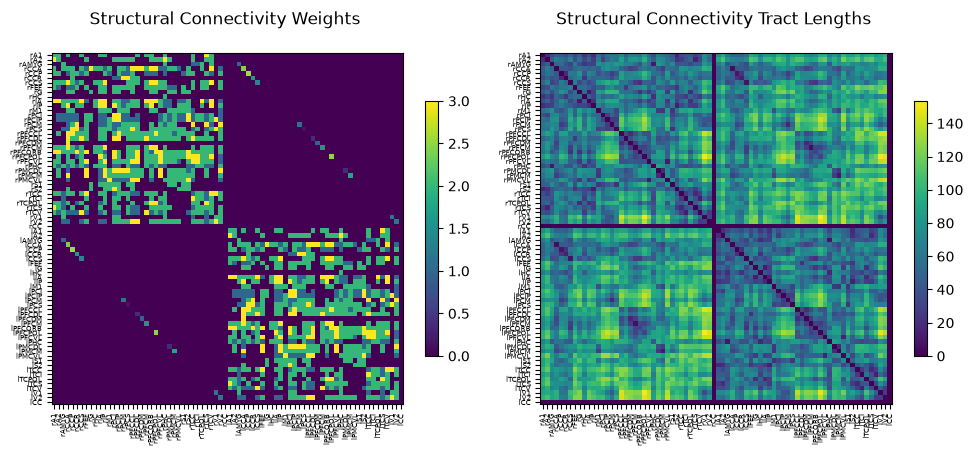

In [18]:
# total number of regions
n_regions = len(my_connectivity.region_labels)

# visualize the connectome
plt.figure(figsize=(10, 7))

plt.subplot(1, 2, 1)
plt.title('Structural Connectivity Weights \n')
plt.imshow(my_connectivity.weights)
plt.colorbar(shrink=0.5)
plt.xticks(np.arange(n_regions), my_connectivity.region_labels, fontsize = 5, rotation=90);
plt.yticks(np.arange(n_regions), my_connectivity.region_labels, fontsize = 5);

plt.subplot(1, 2, 2)
plt.title('Structural Connectivity Tract Lengths \n')
plt.imshow(my_connectivity.tract_lengths)
plt.colorbar(shrink=0.5)
plt.xticks(np.arange(n_regions), my_connectivity.region_labels, fontsize = 5, rotation=90);
plt.yticks(np.arange(n_regions), my_connectivity.region_labels, fontsize = 5);

plt.tight_layout()
plt.gcf().subplots_adjust(bottom=0.25)


### The **Coupling**: how local dynamics communicate with each other

In coupling, you chose the function that joins the local model dynamics at one region to the signals arriving from its connected regions. You find a full description of available coupling ([here] (/bb-coupling/))

In this tutorial, we will use `Linear` coupling. The Global Coupling strength is one of the global model parameters you will need to fine tune to achieve the dynamics you want. An 'optimal' global coupling strength will depend on your individual connectome and local dynamics. Have a look at the section on ([parameter sweeps](/theory/)) to find out more about this. For a full tutorial on how to find the working zone, have a look ([here](/PLACEHOLDER/)). 

For our present purposes, we happen to know that for this configuration of parameters of TVB's Generic2dOscillator connected through TVB's default connectivity matrix, a linear function with a slope of `a = 0.0075` is a reasonable thing to use.

In [19]:
# set coupling
my_coupling = coupling.Linear(a=np.array([0.0075]))

### The **Integrator**: How to move forward in time

The integrator is the numerical scheme stepping the dynamics forward in time. There are integrators with (ie., stochastic integrators) or without noise (ie., deterministic integrators). For a full list of available integrators, have a look ([here](/bb-integrator/)). While TVB supports a number of schemes, for most purposes you should use either HeunDeterministic or HeunStochastic.

A crucial key parameter for every integrator is the time step size. Setting it wrong can have dramatic consequences and produce wrong simulations or yield numerical instability. In ([this resource](/PLACEHOLDER/)) you will find detailed information on how to set the integration time step size and how to identiy and fix failure scenarios. 

If you chose an integrator with noise, another crucial parameter is the noise strength, usually called `Sigma`. 

Just like global coupling strength, the noise strengh sigma is a global model parameters you will need to fine tune to achieve the dynamics you want (ie., the working zone). For a full tutorial on how to find the working zone, have a look ([here](/PLACEHOLDER/)). There are many different types of noise implemented in tvb, all of them are listed ([here](/bb-integrator/))

For our present purposes, we will use Additive noise with a standard deviation of `dt = 0.001`. 

In [20]:
time_step_size = 0.1  # in ms
my_integrator = integrators.HeunDeterministic(dt=time_step_size)

# We could use the deteministic integrator:
# my_det_integrator = integrators.HeunDeterministic(dt=dt)

# Or stochastic integrator:
nsigma = 0.001                    # Standard deviation of the noise
my_noise = noise.Additive(nsig=np.array([nsigma, 0]))
my_stoch_integrator = integrators.HeunStochastic(dt=time_step_size, noise=my_noise)


### **{term}`Monitor <Monitor>`**: How to read-out your signal

Lastly, you need to chose what kind of signal you want your whole-brain model to produce. You can record all state variables of each local model and brain region over time, perform some temporal averaging to save storage space or even apply some biophysical monitors, such as fMRI, EEG or MEG. For a full list of all available monitors, have a look ([here](/bb-monitor/)). 

In this tutorial, we will use the `Raw` monitor to record local state variables of each brain region over time.

In [21]:
my_monitor = monitors.Raw()

## Run the simulation

Now we can finnaly bring all components together in a `Simulator`, configure it, and run it.

In [22]:
# assemble all incredients
my_sim = simulator.Simulator(
    model=my_model,
    connectivity=my_connectivity,
    coupling=my_coupling,
    integrator=my_stoch_integrator,
    monitors=(my_monitor,),
)
my_sim.configure();

2026-11-24 20:18:20,150 - INFO - tvb.simulator.history - history has n_time=513 n_cvar=1 n_node=76 n_nmode=1, requires 0.32 MB
2026-11-24 20:18:20,150 - INFO - tvb.simulator.history - sparse history has n_nnzw=1560, i.e. 27.01 % sparse


Now you can run the simulation using `simulator.run()`. You can chose in simulation_length how much synthetic data you want to geherate. 

Note on runtime: this page deliberately simulates only `10*1e3` ms (10 s) of
activity on the full 76-region connectome — a short run that executes in
seconds and keeps the book's build time well under two minutes on modest
machines. The tradeoff is that the transients below are brief; raise
`simulation_length` (e.g. to `10**13`) for longer recordings at the cost of
slower builds.

In [23]:
sim_length = 10 * 1e3 # ms  

 # Perform the simulation.
tic = tm.time()

(raw_time, raw_data), = my_sim.run(simulation_length=sim_length) 

'simulation required %0.3f seconds.' % (tm.time()-tic)

'simulation required 4.943 seconds.'

In [24]:
f"raw_time: {raw_time.shape} | raw_data: {raw_data.shape}"

'raw_time: (100000,) | raw_data: (100000, 1, 76, 1)'

## Look at the results

The monitor returns two arrays, corresponding to `time` and `data`.
`raw_time` is the timescale of your simulation in ms
`raw_data` has the dimensions *time × 1 × regions × state-variables*.

In the last step, let's visualize the signal.

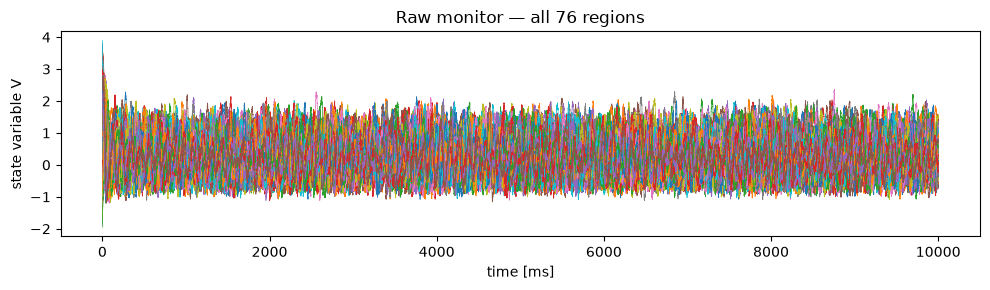

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(raw_time, raw_data[:, 0, :, 0], lw=0.5)
plt.xlabel("Time [ms]")
plt.ylabel("State variable V")
plt.title("Raw monitor — all 76 regions")
plt.tight_layout()
plt.show()

It is usually necessary to remove the transient, which you see in this example as an initial phase where all regions or network nodes 'stabelize' to converge to a common dynamic. In our example, let's remove the first second. 

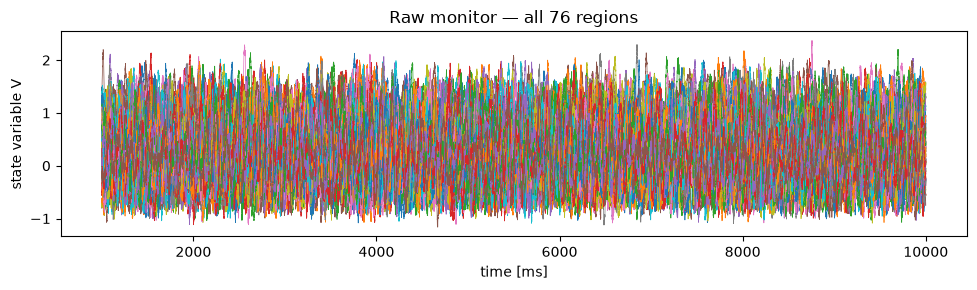

In [ ]:
transient = 1e3 # to remove the first second [in ms]
mask_idx = raw_time >= transient

plt.figure(figsize=(10, 3))
plt.plot(raw_time[mask_idx], raw_data[mask_idx, 0, :, 0], lw=0.5)
plt.xlabel("Time [ms]")
plt.ylabel("State variable V")
plt.title("Raw monitor — all 76 regions")
plt.tight_layout()
plt.show()


### and there you have your first whole-brain stimulated data! 

In [27]:
# Normalize the time series for easier visualization
raw_data_norm = raw_data / (np.max(raw_data, 0) - np.min(raw_data, 0))


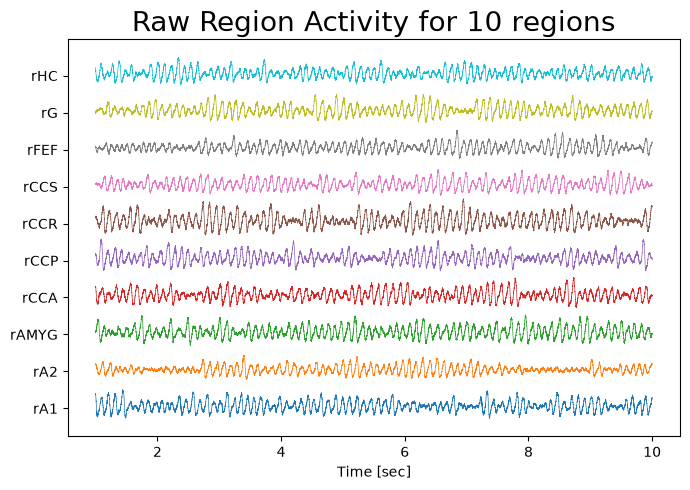

In [29]:
# Plot the raw time series for the first 10 regions
n_plot_regions = 10

plt.figure(figsize=(7, 5))
plt.plot(raw_time[mask_idx]/1e3, raw_data_norm[mask_idx, 0, :n_plot_regions, 0]+ np.r_[:n_plot_regions], lw=0.5)
plt.title(f'Raw Region Activity for {n_plot_regions} regions', fontsize=20)
plt.xlabel('Time [sec]', fontsize=10)
plt.yticks(range(10), my_connectivity.region_labels[:n_plot_regions], fontsize=10)

plt.tight_layout()
plt.show()



You have now run the full TVB chain: local dynamics propagated over a
structural connectome and observed by monitors.